<a href="https://colab.research.google.com/github/tbeucler/2026_ECMWF_MOOC/blob/main/mcausal_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced Tutorial: Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting (CausalSHIPS)

Welcome to this advanced module on **Multidata Causal Discovery** for Earth system modeling. This tutorial demonstrates how to implement the **Multi-dataset Peter–Clark (M-PC)** algorithm for targeted feature selection to enhance statistical predictions of tropical cyclone (TC) intensity change ($\Delta V_{24}$), based on the methodology established by *Ganesh et al. (2026)* in *Weather and Forecasting*[cite: 1].

### Operational & Scientific Context
Numerical Weather Prediction (NWP) and statistical-dynamical models (such as SHIPS) often ingest hundreds of high-dimensional reanalysis and observational predictors. Traditional statistical and machine learning methods frequently fall victim to **multicollinearity, spurious correlations, and overfitting**, latching onto redundant vertical shear proxies or outer-core moisture variables.

Rather than attempting to map the entire end-to-end causal graph of the tropical cyclone boundary layer, this tutorial addresses **single-target asymmetric causal feature selection ($\mathbf{X} \to Y$)**[cite: 1]. We isolate a parsimonious, robust subset of physical drivers directly linked to future intensity changes, establishing a bridge between rigorous causality theory and operational forecasting frameworks[cite: 1].

The objective is not to reconstruct the complete causal network of the tropical cyclone system. Instead, we use multiple TC realizations to identify a **subset of predictors that retain causal relationships with future intensity change**, and then evaluate whether these predictors are useful for statistical forecasting.


---

## 1. Scientific Background & Architecture

### Core Methodology: Multi-Dataset Peter–Clark (M-PC)
* **Disjoint Time Series Handling**: Traditional time-series causal discovery assumes a single continuous stationary sequence. Extreme weather data consists of similar **multiple disjoint multivariate time series** .
For example: Tropical cyclone dataset consist of multiple **disjoint multivariate time series**, with each storm representing a separate realization of the underlying dynamical system. Treating these storms as one continuous time series would introduce artificial dependencies at storm boundaries.

The **Multidata Peter–Clark (M-PC)** framework pools conditional independence tests across independent storm records without artificial concatenation, preventing cross-storm boundary contamination. This allows information from different storms to contribute to the estimation of a common causal structure.


 **Single-Target Asymmetric Selection ($\mathbf{X} \to Y$)**: Rather than estimating a full $214 \times 214$ inter-predictor network, CausalSHIPS targets **single-target physical predictor selection**, directly identifying the causal parents $\hat{\mathcal{P}}(Y)$ of future intensity change ($Y = \Delta V_{24}$) [cite: 1, 2].

In CausalSHIPS Project, the objective is **target-oriented causal feature selection** identifying the predictors that are causally linked to the target:

\[
Y = $\Delta V_{24}$
\],

where $\Delta V_{24}$ represents the 24-hour change in tropical cyclone intensity.

The resulting causal predictor set can then be supplied to a downstream statistical or machine-learning forecasting model.

---

## 2. Learning Objectives
1. **Data Ingestion**: Load multi-storm ERA5 and TC PRIMED area-averaged preprocessed tensor datasets[cite: 1, 2].
2. **M-PC Execution**: Run the Multi-dataset Peter–Clark conditional independence sweep[cite: 1].
3. **Hyperparameter Tuning**: Evaluate model parsimony across significance thresholds to choose the best predictor set ($pc_\alpha$)[cite: 1, 2].
4. **Benchmarking**: Compare M-PC against traditional correlation ranking and Random Forest feature importance[cite: 1].

---

## 3. Workflow Scope: Paper vs. Tutorial

> 📌 **Important Distinction for Learners:**
> * **Figure 1 (Global Pipeline):** Represents the full study's multi-fold cross-validation and consensus aggregation across 247 North Atlantic storms (2000–2021)[cite: 2].
> * **This Notebook:** Focuses on an executable, streamlined implementation for **Fold 3** to demonstrate local feature pruning, regression benchmarking, and out-of-sample trajectory verification[cite: 1].


---
   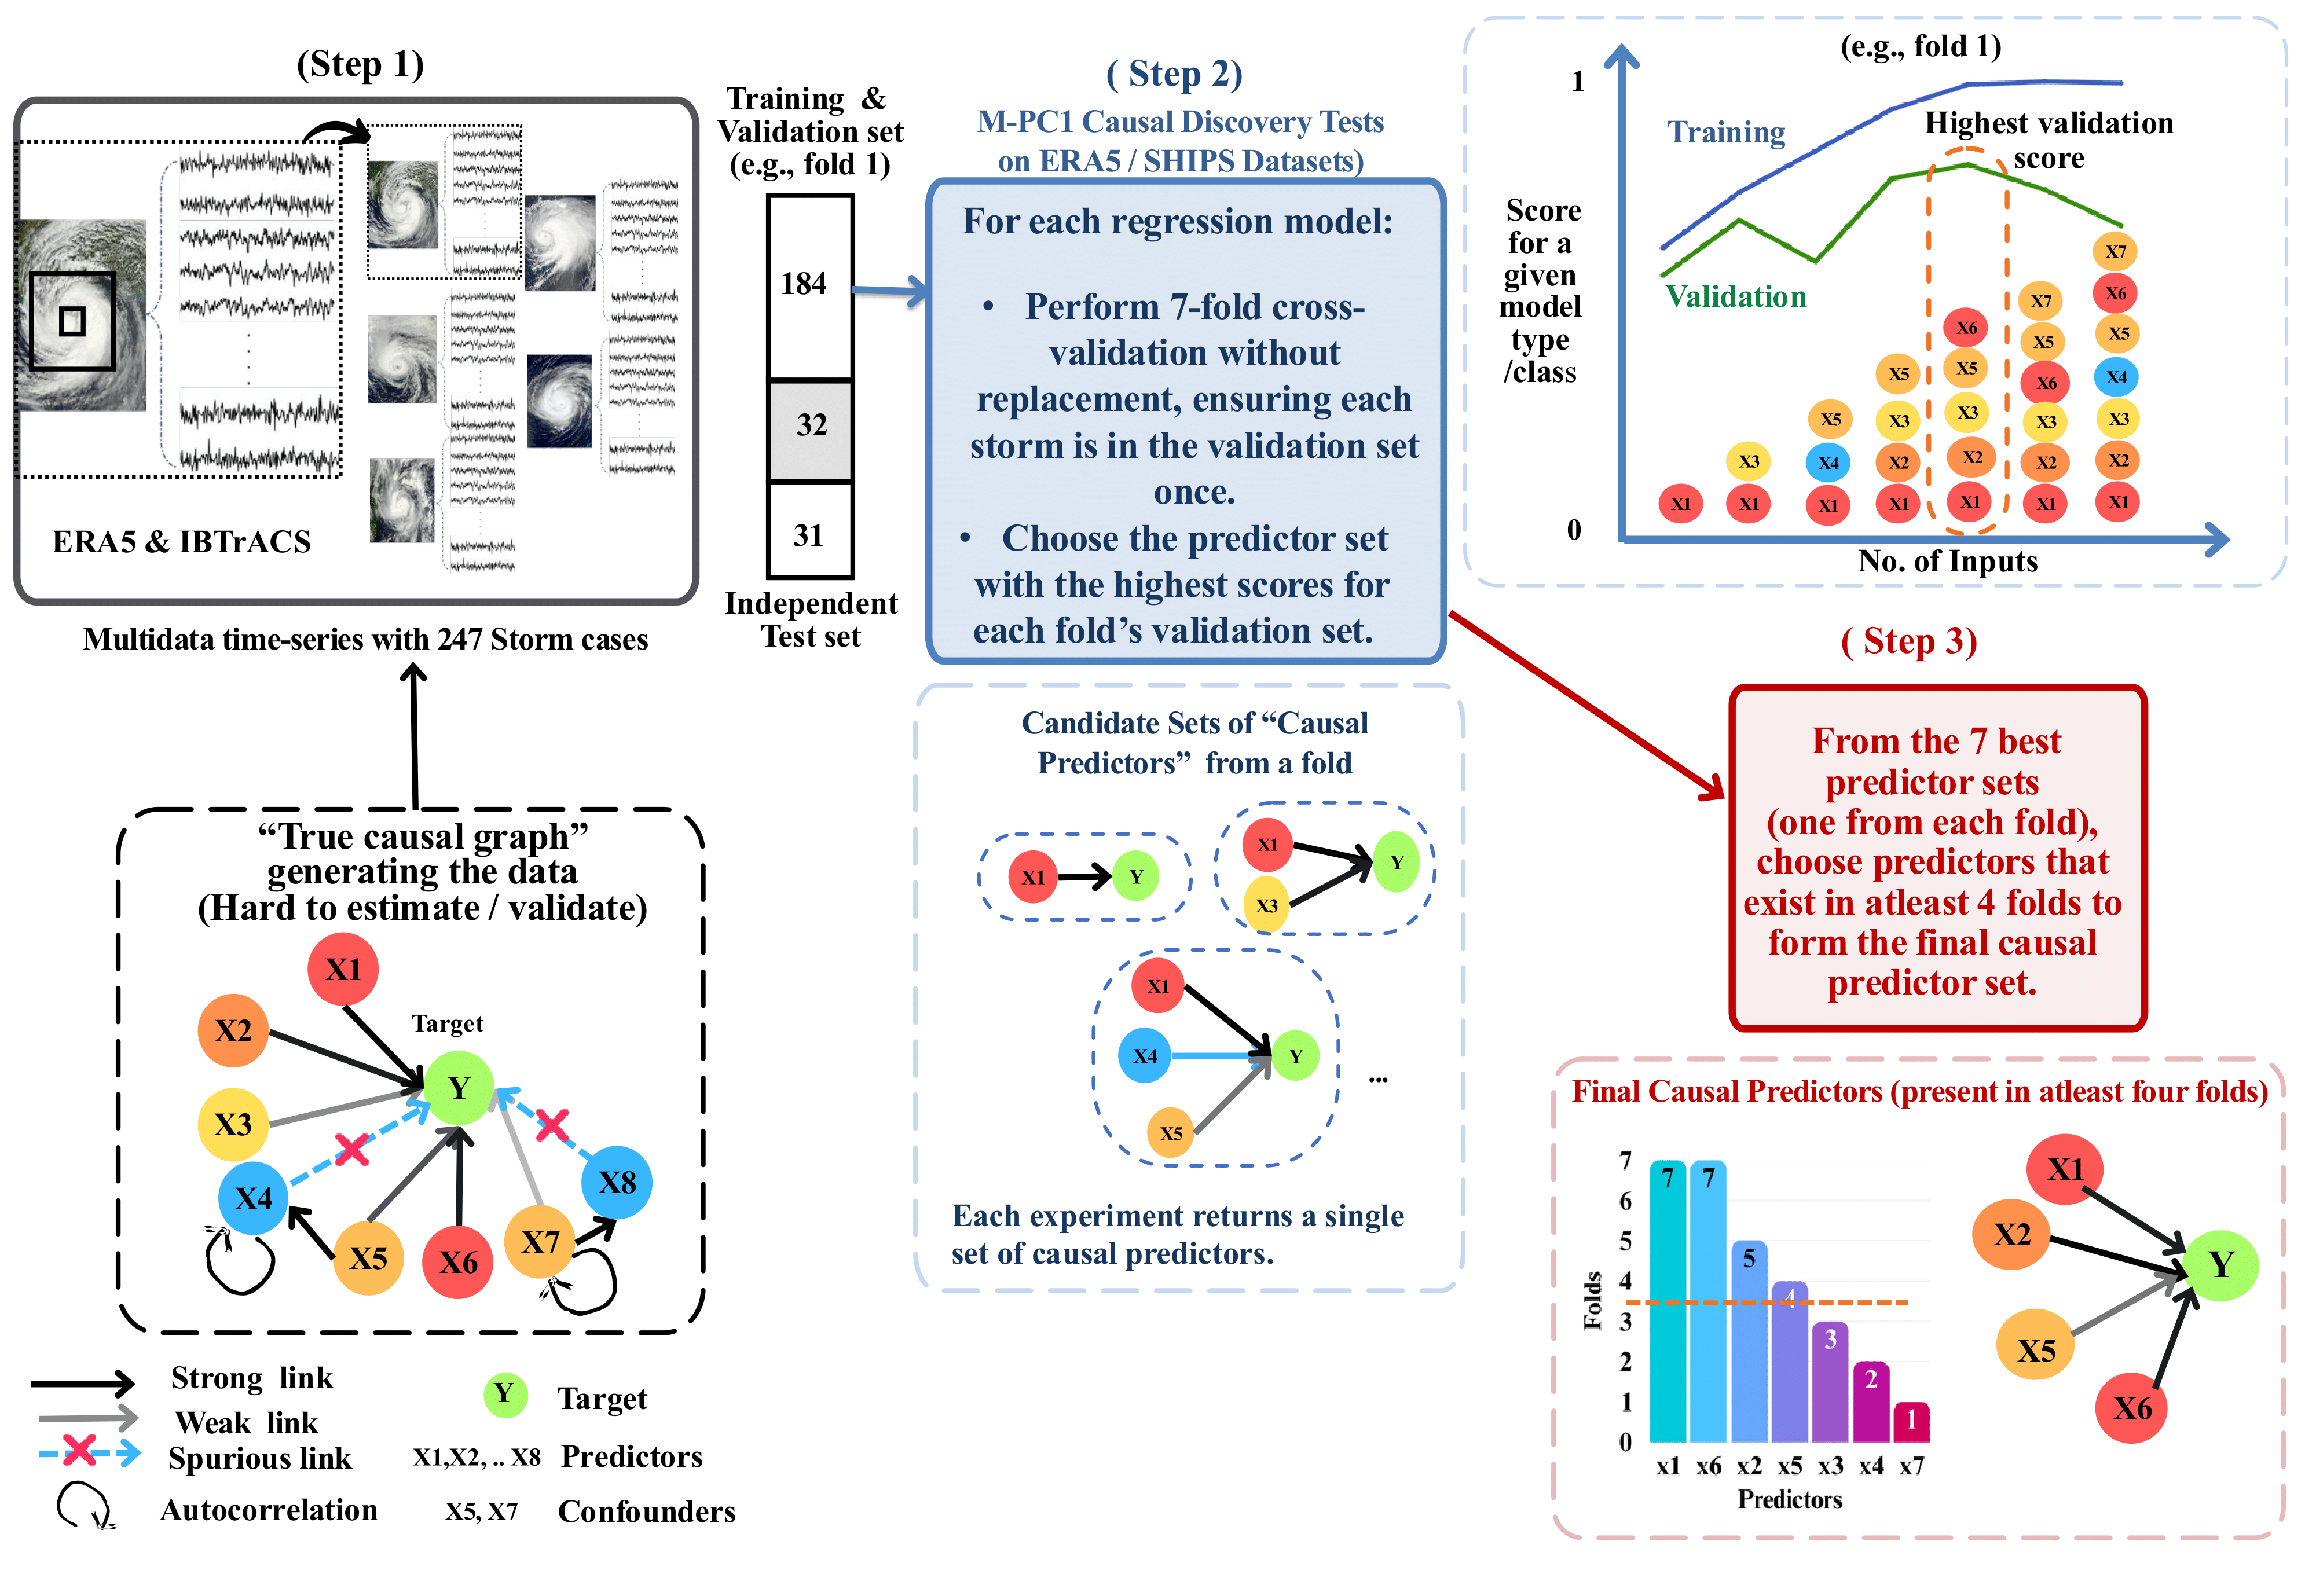


---
### Reference & Citation
* **Primary Journal Article**: Ganesh, S. S., F. I.-H. Tam, M. S. Gomez, M. McGraw, M. DeMaria, K. Musgrave, J. Runge, and T. Beucler, 2026: *Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. *Weather and Forecasting*, **41** (7), 1359–1375 [DOI: 10.1175/WAF-D-25-0208.1](https://doi.org/10.1175/WAF-D-25-0208.1)
* **Supplementary Information (SI)**: Ganesh et al. (2026): *Supplementary Information: Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. *Weather and Forecasting* [DOI: 10.1175/WAF-D-25-0208.s1](https://doi.org/10.1175/WAF-D-25-0208.s1)
* **Code & Data Repository**: [GitHub (saranya8989/2025_CausalSHIPS)](https://github.com/saranya8989/2025_CausalSHIPS) | [Zenodo Archive (DOI: 10.5281/zenodo.17242382)](https://doi.org/10.5281/zenodo.17242382)
---

## Step 1: Environment Setup & Library Imports

In this first step, we import the necessary scientific computing libraries and the core causal discovery framework, **Tigramite**, which provides the multi-dataset Peter–Clark (M-PC) implementation (*Runge, 2018; Ganesh et al., 2026*)[cite: 1, 3].

In [ ]:
# Run this cell if executing in Google Colab
!pip install -q tigramite tqdm scikit-learn seaborn matplotlib pandas numpy scipy requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.7/314.7 kB 9.2 MB/s eta 0:00:00


In [ ]:
# ==============================================================================
# Cell 1: Environment Setup & Dependencies
# ==============================================================================
import os
import glob
import sys
import pickle
import collections
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
from scipy import stats

# Scikit-Learn Benchmarking
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Tigramite Causal Discovery Framework
import tigramite
from tigramite.data_processing import DataFrame
from tigramite.independence_tests.parcorr import ParCorr
from tigramite.pcmci import PCMCI

# Visualization Setup
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("All dependencies successfully imported!")

All dependencies successfully imported!


## Step 1B: Repository cloning and Data Synchronization

To ensure this notebook runs smoothly in cloud environments like Google Colab, we automatically synchronize the required data assets and scripts directly from the official **CausalSHIPS** GitHub repository (`saranya8989/2025_CausalSHIPS`).

This step clones the project directory and verifies the location of the preprocessed `data_for_tigramite` tensors required for the M-PC causal discovery workflow.

In [ ]:
# ==============================================================================
# Cell 1B: Automated Repository Clone & Data Loading from GitHub
# ==============================================================================
import os

repo_name = "2025_CausalSHIPS"
repo_url = f"https://github.com/saranya8989/{repo_name}.git"

if not os.path.exists(repo_name):
    print(f"Cloning {repo_name} repository from GitHub...")
    !git clone -q {repo_url}
    print("Repository cloned successfully.")
else:
    print(f"Repository '{repo_name}' already exists locally.")

# Set working directory or ensure path alignment for Step 2
# This maps your data_for_tigramite folder instantly inside the Colab environment
data_path = os.path.join(repo_name, "data_for_tigramite")
if os.path.exists(data_path):
    print(f"Data directory verified at: {data_path}")
else:
    print("Warning: 'data_for_tigramite' folder not found in the root. Check repo folder structure.")

Cloning 2025_CausalSHIPS repository from GitHub...
Repository cloned successfully.
Data directory verified at: 2025_CausalSHIPS/data_for_tigramite


## Step 2: Data Ingestion (Fold 3 - Multi-Storm ERA5 Predictors)

In this step, we load **Fold 3** of the preprocessed dataset (`tigramite_ready_dataset_delv24_3.pkl`) (*Ganesh et al., 2026*):

* **Target Predictand ($Y$)**: 24-hour maximum surface wind speed change ($\text{DELV24} = \Delta V_{24}$ in kt)[cite: 1].
* **Candidate Predictors ($\mathbf{X}$)**: 214 atmospheric variables derived from ERA5 reanalysis and TC PRIMED, comprising replicated SHIPS predictors and multi-level area-averaged thermodynamic/kinematic fields[cite: 1].
* **Storm-Level Partition**: The dataset is split at the **storm level** (70% Train, 15% Validation, 15% Unseen Test) to ensure that observations from the same storm lifecycle are never leaked across training and evaluation partitions[cite: 1].

In [ ]:
# ==============================================================================
# Cell 2: Multi-Storm Dataset check & Storm-Level Partition
# ==============================================================================
# Updated target directory pointing to the local cloned repository structure
target_dir = "2025_CausalSHIPS/data_for_tigramite"
os.makedirs(target_dir, exist_ok=True)

# Locate Fold 3 pickle
fold3_pkls = glob.glob(f"{target_dir}/*delv24_3.pkl") or glob.glob("**/tigramite_ready_dataset_delv24_3.pkl", recursive=True)

if not fold3_pkls:
    zip_files = glob.glob(f"{target_dir}/*delv24_3.zip") or glob.glob("**/tigramite_ready_dataset_delv24_3.zip", recursive=True)
    if zip_files:
        with zipfile.ZipFile(zip_files[0], 'r') as zip_ref:
            zip_ref.extractall(target_dir)
        fold3_pkls = glob.glob(f"{target_dir}/*delv24_3.pkl")

target_pkl = fold3_pkls[0]
print(f"Checking preprocessed dataset created from ERA5: {target_pkl}")

with open(target_pkl, 'rb') as f:
    fold_dict = pickle.load(f)

var_names = list(fold_dict['var_names'])
target_name = var_names[0]
feature_names = var_names[1:]

raw_storm_dict = fold_dict.get('aligned_train', fold_dict.get('Xnorml', fold_dict.get('storm_dict')))
storm_ids = list(raw_storm_dict.keys())

# Storm-level partitioning (70% Train, 15% Validation, 15% Unseen Test)
n_tr = int(0.70 * len(storm_ids))
n_val = int(0.15 * len(storm_ids))

train_keys = storm_ids[:n_tr]
val_keys   = storm_ids[n_tr:n_tr + n_val]
test_keys  = storm_ids[n_tr + n_val:]

def stack_split(keys):
    stacked = np.vstack([
        raw_storm_dict[k].values if hasattr(raw_storm_dict[k], 'values') else np.asarray(raw_storm_dict[k])
        for k in keys
    ])
    X = stacked[:, 1:]
    y = stacked[:, 0]
    valid_mask = ~np.isnan(X).any(axis=1) & ~np.isnan(y)
    return X[valid_mask], y[valid_mask]

X_tr, y_tr   = stack_split(train_keys)
X_val, y_val = stack_split(val_keys)
X_te, y_te   = stack_split(test_keys)

print("=" * 75)
print(f"MULTI-STORM DATASET LOADED: {os.path.basename(target_pkl)}")
print("=" * 75)
print(f"Target Predictand        : {target_name}")
print(f"Candidate Predictor Pool : {len(feature_names)} atmospheric variables")
print(f"Training Samples         : {X_tr.shape[0]} ({len(train_keys)} storms)")
print(f"Validation Samples       : {X_val.shape[0]} ({len(val_keys)} storms)")
print(f"Test Samples (Unseen)    : {X_te.shape[0]} ({len(test_keys)} storms)")
print(f"Mean DELV24 (Train): {np.mean(y_tr):.2f} kt")

Ingesting pre-computed dataset: 2025_CausalSHIPS/data_for_tigramite/tigramite_ready_dataset_delv24_3.pkl
MULTI-STORM DATASET LOADED: tigramite_ready_dataset_delv24_3.pkl
Target Predictand        : delv24
Candidate Predictor Pool : 214 atmospheric variables
Training Samples         : 4179 (128 storms)
Validation Samples       : 944 (27 storms)
Test Samples (Unseen)    : 1039 (29 storms)
Mean DELV24 (Train): 0.21 kt


---

## 3. Executing the M-PC Causal Discovery Sweep

With our environment paths configured and multi-storm data loaded for **Fold 3**, we initiate the M-PC significance sweep[cite: 1].

### Operational Execution Mechanics
* **Encoding Domain Expertise:** We import our custom physical link constraints (`link_shipsera5`) to constrain the PCMCI algorithm, ensuring it only evaluates permissible physical lags and prevents spurious cross-variable linkages[cite: 1].
* **The Significance Grid (`pc_alpha`):** We loop across an alpha significance grid ranging from strict thresholds ($0.0001$) to looser bounds ($0.5$). This sweep governs the rejection threshold for conditional independence tests using Partial Correlation (`ParCorr`).
* **Caching Results:** Because executing conditional independence tests across high-dimensional meteorological tensors is computationally intensive, the resulting graphs and metrics for each alpha level are packaged and saved locally as a pickle archive for downstream evaluation[cite: 1].

The script below executes this multi-step workflow cleanly and saves the output package[cite: 1].

In [ ]:
# ==============================================================================
# Cell 3: Run the M-PC Significance Alpha Sweep & Save Results (Kernel-Safe)
# ==============================================================================
import pickle
import gc
import os
import sys
import numpy as np
from tqdm.auto import tqdm
from tigramite.independence_tests.parcorr import ParCorr

# 1. Add the nested models directory to sys.path so Python can find them
models_dir = os.path.abspath("2025_CausalSHIPS/util/models")
if models_dir not in sys.path:
    sys.path.append(models_dir)

import causal_settings
import train_PC1

fold = 3
lag = 4

# 2. Load pre-packed fold dataset (located in the root project data directory)
data_path = f'2025_CausalSHIPS/data_for_tigramite/tigramite_ready_dataset_delv24_{fold}.pkl'
print(f"Loading data from: {data_path}")
TIDATA = pickle.load(open(data_path, 'rb'))

# Extract variable names from training dataframe columns
first_key = list(TIDATA['Xnorml']['train'].keys())[0]
var_names = list(TIDATA['Xnorml']['train'][first_key].columns)
print(f"Loaded {len(var_names)} variables. Target predictand: {var_names[0]}")

# 3. Setup link assumptions
onlyships_lag = causal_settings.link_shipsera5(
    numvar=len(var_names),
    lag=lag,
    target_ind=[0]  # delv24 is index 0
)

# Alpha significance grid matching paper
pc_alpha_grid = [
    0.0001, 0.00015, 0.001, 0.0015, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06,
    0.07, 0.08, 0.09, 0.1, 0.15, 0.2, 0.25, 0.30, 0.35, 0.4, 0.45, 0.5
]

results = []
for pc_alpha in tqdm(pc_alpha_grid, desc=f"M-PC Sweep (Fold {fold})"):
    # Format multi-storm dictionaries with missing values handled (-999.0)
    Xnorml_c = {
        'train': {ind: np.asarray(TIDATA['Xnorml']['train'][key].replace(np.nan, -999.0))
                  for ind, key in enumerate(TIDATA['Xnorml']['train'].keys())},
        'valid': {ind: np.asarray(TIDATA['Xnorml']['valid'][key].replace(np.nan, -999.0))
                  for ind, key in enumerate(TIDATA['Xnorml']['valid'].keys())},
        'test': {ind: np.asarray(TIDATA['Xnorml']['test'][key].replace(np.nan, -999.0))
                 for ind, key in enumerate(TIDATA['Xnorml']['test'].keys())}
    }

    pipeline_run = train_PC1.Pipeline(
        data=Xnorml_c['train'],
        pc_alpha=pc_alpha,
        pc_type='run_pcstable',
        tau_min0=0,
        tau_max0=lag,
        var_name=var_names,
        cond_ind_test=ParCorr(),
        link_assumptions=onlyships_lag
    )

    result = pipeline_run.run_tigramite()
    results.append(result)

    del Xnorml_c
    gc.collect()

# 4. Save results package
saveto = {
    'dataframes': TIDATA['Xnorml'],
    'PC1_results': results,
    'var_names': var_names
}

out_dir = f"results/{lag}/SHIPSERA5_noassum/"
os.makedirs(out_dir, exist_ok=True)
out_file = os.path.join(out_dir, f"results_fold_{fold}.pkl")

with open(out_file, 'wb') as handler:
    pickle.dump(saveto, handler)

print("=" * 80)
print(f"M-PC Sweep Completed & Saved Successfully to: {out_file}")
print("=" * 80)

Loading data from: 2025_CausalSHIPS/data_for_tigramite/tigramite_ready_dataset_delv24_3.pkl
Loaded 215 variables. Target predictand: delv24


M-PC Sweep (Fold 3):   0%|          | 0/22 [00:00<?, ?it/s]

M-PC Sweep Completed & Saved Successfully to: results/4/SHIPSERA5_noassum/results_fold_3.pkl


---

---

## 4. Evaluating Causal Subsets & Optimizing Model Parsimony

Once the Multi-dataset Peter–Clark (M-PC) algorithm has mapped the conditional independence structure across our significance grid ($\alpha$), we must determine which subset of discovered drivers yields the most robust out-of-sample forecast.

### The Significance Sweep & Parsimony Trade-off
* **The Role of $\alpha$:** The significance threshold ($pc_\alpha$) controls how stringent the conditional independence tests are. Stricter (lower) $\alpha$ values yield sparser graphs with fewer predictors, while looser values admit more potential drivers.
* **Downstream Multiple Linear Regression (MLR):** To evaluate the predictive utility of the discovered causal parents, we train an ordinary least squares Multiple Linear Regression model on each alpha configuration's selected subset[cite: 1].
* **Selecting the Optimal Model:** By evaluating performance across a validation split, we identify the peak configuration that avoids both underfitting (missing critical physical drivers) and overfitting (retaining noisy, multicollinear covariates).

In the code block below, we load the saved sweep results, map Tigramite's absolute variable indices back to our predictor array, and extract the peak performing feature subset for downstream verification[cite: 1].



In [ ]:
# ==============================================================================
# Cell 4 : MLR Evaluation & Feature Name Mapping for Fold 3
# ==============================================================================
import pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from tqdm.auto import tqdm

fold = 3
lag = 4
pkl_path = f"results/{lag}/SHIPSERA5_noassum/results_fold_{fold}.pkl"

# 1. Load saved M-PC results
print(f"Loading saved causal results from: {pkl_path}")
with open(pkl_path, 'rb') as f:
    saved_data = pickle.load(f)

results = saved_data['PC1_results']
var_names = list(saved_data['var_names'])
target_name = var_names[0]
feature_names = var_names[1:]

# Alpha grid matching your sweep
pc_alpha_grid = [
    0.0001, 0.00015, 0.001, 0.0015, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06,
    0.07, 0.08, 0.09, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5
]

evaluation_records = []

# 2. Iterate through each alpha's causal dictionary and evaluate MLR performance
for idx, pc_alpha in enumerate(tqdm(pc_alpha_grid, desc="Evaluating MLR on Causal Subsets")):
    res = results[idx]

    # Target causes are stored under key 0: list of tuples like (pred_var_idx, lag)
    target_causes = res.get(0, [])

    selected_indices = []
    for pred_idx, lag_val in target_causes:
        # map back to feature array index (since index 0 is target delv24)
        feat_idx = int(pred_idx) - 1
        if 0 <= feat_idx < len(feature_names) and feat_idx not in selected_indices:
            selected_indices.append(feat_idx)

    # Fallback safety if graph is completely sparse at strict alpha
    if len(selected_indices) == 0:
        selected_indices = [0]  # fallback index

    # Subset data for MLR (assuming X_tr, X_val, X_te, y_tr, y_val, y_te are loaded)
    X_tr_sub = X_tr[:, selected_indices]
    X_val_sub = X_val[:, selected_indices]
    X_te_sub = X_te[:, selected_indices]

    # Fit Multiple Linear Regression
    mlr = LinearRegression()
    mlr.fit(X_tr_sub, y_tr)

    # Compute R² scores
    tr_r2  = r2_score(y_tr, mlr.predict(X_tr_sub))
    val_r2 = r2_score(y_val, mlr.predict(X_val_sub))
    te_r2  = r2_score(y_te, mlr.predict(X_te_sub))

    evaluation_records.append({
        'pc_alpha': pc_alpha,
        'num_vars': len(selected_indices),
        'selected_indices': selected_indices,
        'selected_features': [feature_names[i] for i in selected_indices],
        'train_r2': tr_r2,
        'val_r2': val_r2,
        'test_r2': te_r2,
        'model': mlr
    })

# Convert to DataFrame for analysis
causal_eval_df = pd.DataFrame(evaluation_records)

# Identify peak validation performance
peak_row = causal_eval_df.loc[causal_eval_df['val_r2'].idxmax()]
causal_res = {
    'Method': 'Causal M-PC + MLR',
    'Predictors': peak_row['num_vars'],
    'Train R2': peak_row['train_r2'],
    'Validation R2': peak_row['val_r2'],
    'Test R2 (Unseen)': peak_row['test_r2'],
    'Selected Features': peak_row['selected_features'],
    'Indices': peak_row['selected_indices'],
    'Model': peak_row['model']
}

print("=" * 80)
print(f"PEAK CAUSAL MLR CONFIGURATION (Fold {fold}):")
print(f"  - pc_alpha       : {peak_row['pc_alpha']}")
print(f"  - Selected Vars (K): {peak_row['num_vars']}")
print(f"  - Train R²       : {peak_row['train_r2']:.4f}")
print(f"  - Validation R²  : {peak_row['val_r2']:.4f}")
print(f"  - Test R² (Unseen): {peak_row['test_r2']:.4f}")
print("=" * 80)
print("\nSelected Features for Peak Model:")
for i, feat in enumerate(peak_row['selected_features'], 1):
    print(f"{i:2d}. {feat}")

Loading saved causal results from: results/4/SHIPSERA5_noassum/results_fold_3.pkl


Evaluating MLR on Causal Subsets:   0%|          | 0/22 [00:00<?, ?it/s]

PEAK CAUSAL MLR CONFIGURATION (Fold 3):
  - pc_alpha       : 0.1
  - Selected Vars (K): 13
  - Train R²       : 0.2096
  - Validation R²  : 0.1985
  - Test R² (Unseen): 0.2268

Selected Features for Peak Model:
 1. wind10
 2. sdir
 3. shear_1000_850.1
 4. outrhum_1000
 5. outrhum_850
 6. shear_850_300
 7. tgrad_200_800
 8. tadv
 9. rhum_400
10. vort_700
11. outpvor_250
12. shear_1000_200.1
13. rh_0_500_1000


## Step 4: Comparative Baseline Benchmarking
To rigorously evaluate the efficacy of causal feature selection, we benchmark our **Causal M-PC + Multiple Linear Regression (MLR)** architecture against three standard paradigms[cite: 1]:
1. **Correlation Feature Selection + MLR**: Ranking features by absolute Pearson correlation with the target[cite: 1].
2. **Random Forest Feature Importance + MLR**: Selecting top-ranked features derived from unconstrained tree-based variance reduction[cite: 1].
3. **Full Model (All 214 Features, No FS)**: Retaining the entire high-dimensional feature space to illustrate the risks of parameter bloat and multicollinearity in numerical post-processing[cite: 1].

In [ ]:
# ==============================================================================
# Cell 4B : Baseline Feature Sweeps and Model Comparison
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from tqdm.auto import tqdm

# 1. Compute Pearson correlation with target for baseline ranking
print("Computing Pearson correlation ranking across feature pool...")
corr_with_y = np.array([np.corrcoef(X_tr[:, i], y_tr)[0, 1] for i in range(X_tr.shape[1])])
corr_with_y = np.nan_to_num(corr_with_y, nan=0.0)  # handle any constant columns safely
corr_ranked = np.argsort(np.abs(corr_with_y))[::-1]

# 2. Fit Random Forest feature importance baseline
print("Fitting Random Forest feature importance baseline...")
rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
rf_ranked = np.argsort(rf.feature_importances_)[::-1]

def sweep_baseline(rank_order, label, max_features=30):
    best_v = -np.inf
    best_k = 1
    best_tr, best_te = 0.0, 0.0
    best_m = None

    k_range = list(range(1, min(max_features + 1, len(rank_order) + 1)))
    pbar = tqdm(k_range, desc=f"Sweeping {label}", leave=False, unit="model_size")

    for k in pbar:
        sub = rank_order[:k]
        m = LinearRegression()
        m.fit(X_tr[:, sub], y_tr)
        v_r2 = r2_score(y_val, m.predict(X_val[:, sub]))
        if v_r2 > best_v:
            best_v, best_k, best_m = v_r2, k, m
            best_tr = r2_score(y_tr, m.predict(X_tr[:, sub]))
            best_te = r2_score(y_te, m.predict(X_te[:, sub]))
        pbar.set_postfix({'Best K': best_k, 'Best Val R²': f"{best_v:.3f}"})

    return {
        'Method': label,
        'Predictors': best_k,
        'Train R2': best_tr,
        'Validation R2': best_v,
        'Test R2 (Unseen)': best_te,
        'Selected Features': [feature_names[i] for i in rank_order[:best_k]],
        'Indices': rank_order[:best_k],
        'Model': best_m
    }

print("Running sequential feature sweeps for baselines...")
corr_best = sweep_baseline(corr_ranked, "Correlation FS + MLR")
rf_best   = sweep_baseline(rf_ranked, "Random Forest FS + MLR")

# 3. Full Model Baseline (No Feature Selection)
m_all = LinearRegression()
m_all.fit(X_tr, y_tr)
all_res = {
    'Method': "All 214 Features (No FS)",
    'Predictors': len(feature_names),
    'Train R2': r2_score(y_tr, m_all.predict(X_tr)),
    'Validation R2': r2_score(y_val, m_all.predict(X_val)),
    'Test R2 (Unseen)': r2_score(y_te, m_all.predict(X_te)),
    'Selected Features': "All 214 Predictors",
    'Indices': list(range(len(feature_names))),
    'Model': m_all
}

# 4. Compile and Display Summary Table
summary_table = pd.DataFrame([causal_res, corr_best, rf_best, all_res])
print("\n" + "=" * 85)
print("FINAL BENCHMARK COMPARISON ON UNSEEN TEST STORMS")
print("=" * 85)
display(summary_table[['Method', 'Predictors', 'Train R2', 'Validation R2', 'Test R2 (Unseen)', 'Selected Features']])

Computing Pearson correlation ranking across feature pool...
Fitting Random Forest feature importance baseline...
Running sequential feature sweeps for baselines...


Sweeping Correlation FS + MLR:   0%|          | 0/30 [00:00<?, ?model_size/s]

Sweeping Random Forest FS + MLR:   0%|          | 0/30 [00:00<?, ?model_size/s]


FINAL BENCHMARK COMPARISON ON UNSEEN TEST STORMS


,Method,Predictors,Train R2,Validation R2,Test R2 (Unseen),Selected Features
0,Causal M-PC + MLR,13,0.209646,0.198490,0.226813,"[wind10, sdir, shear_1000_850.1, outrhum_1000,..."
1,Correlation FS + MLR,28,0.244790,0.265793,0.207117,"[shear_1000_850, shear_1000_700, pvor_700, pvo..."
2,Random Forest FS + MLR,30,0.298428,0.272435,0.297324,"[shear_1000_850, wind10, pvor_850, pvor_700, p..."
3,All 214 Features (No FS),214,0.455840,0.347666,0.008257,All 214 Predictors


---

## 5. Non-linear Generalization: Pairing Causal Drivers with Neural Networks

While Multiple Linear Regression (MLR) provides a transparent, exact baseline for evaluating our discovered causal parents, atmospheric dynamics are inherently non-linear.

### Bridging Causality and Non-Linearity
* **The Role of Neural Networks:** By feeding our parsimonious causal subset into a Multi-Layer Perceptron (MLP) regressor, we can test whether non-linear interactions between these physical drivers can capture more variance in rapid intensity changes ($\Delta V_{24}$).
* **Regularization & Prevention of Overfitting:** High-dimensional data and deep networks easily overfit. To maintain operational rigor, our MLP uses $L2$ regularization ($\alpha=0.01$) and validation-based early stopping.
* **Evaluating the Architecture:** This allows us to assess whether causal feature selection successfully acts as an agnostic pre-filter that enhances both linear and non-linear machine learning models alike.

In the cell below, we train the MLP regressor using the exact same causal feature subset and update our final benchmark comparison table[cite: 1].

In [ ]:
# ==============================================================================
# Cell 5: Training & Evaluating an MLP on Causal Features
# ==============================================================================
from sklearn.neural_network import MLPRegressor

print("Training MLP Regressor on Causal M-PC features...")

# Extract causal subset data
X_tr_causal = X_tr[:, peak_row['selected_indices']]
X_val_causal = X_val[:, peak_row['selected_indices']]
X_te_causal = X_te[:, peak_row['selected_indices']]

# Initialize and train MLP (using early stopping to prevent overfitting)
mlp = MLPRegressor(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    alpha=0.01,          # L2 regularization penalty
    max_iter=500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.15
)

mlp.fit(X_tr_causal, y_tr)

# Evaluate performance
mlp_tr_r2  = r2_score(y_tr, mlp.predict(X_tr_causal))
mlp_val_r2 = r2_score(y_val, mlp.predict(X_val_causal))
mlp_te_r2  = r2_score(y_te, mlp.predict(X_te_causal))

mlp_res = {
    'Method': 'Causal M-PC + MLP',
    'Predictors': peak_row['num_vars'],
    'Train R2': mlp_tr_r2,
    'Validation R2': mlp_val_r2,
    'Test R2 (Unseen)': mlp_te_r2,
    'Selected Features': peak_row['selected_features'],
    'Indices': peak_row['selected_indices'],
    'Model': mlp
}

print(f"MLP Training Complete!")
print(f"  - Train R²       : {mlp_tr_r2:.4f}")
print(f"  - Validation R²  : {mlp_val_r2:.4f}")
print(f"  - Test R² (Unseen): {mlp_te_r2:.4f}")

# Re-compile Summary Table including the MLP benchmark
summary_table_with_mlp = pd.DataFrame([causal_res, mlp_res, corr_best, rf_best, all_res])

print("\n" + "=" * 90)
print("FINAL BENCHMARK COMPARISON INCLUDING CAUSAL MLP")
print("=" * 90)
display(summary_table_with_mlp[['Method', 'Predictors', 'Train R2', 'Validation R2', 'Test R2 (Unseen)']])

Training MLP Regressor on Causal M-PC features...
MLP Training Complete!
  - Train R²       : 0.4322
  - Validation R²  : 0.3494
  - Test R² (Unseen): 0.3230

FINAL BENCHMARK COMPARISON INCLUDING CAUSAL MLP


,Method,Predictors,Train R2,Validation R2,Test R2 (Unseen)
0,Causal M-PC + MLR,13,0.209646,0.198490,0.226813
1,Causal M-PC + MLP,13,0.432245,0.349399,0.323027
2,Correlation FS + MLR,28,0.244790,0.265793,0.207117
3,Random Forest FS + MLR,30,0.298428,0.272435,0.297324
4,All 214 Features (No FS),214,0.455840,0.347666,0.008257


---

## 6. Out-of-Sample Trajectory Verification on Unseen Storms

Aggregate $R^2$ metrics provide a macro-level evaluation, but operational meteorology demands temporal stability across individual storm lifecycles.

In this section, we scan unseen test storm trajectories, compute localized skill scores, and perform a comparative trajectory analysis against ground-truth $\Delta V_{24}$ evolution[cite: 1]. This highlights how parsimonious causal drivers maintain robustness during critical intensity shifts (e.g., rapid intensification or baroclinic transition phases) where unconstrained models often overfit.


Top Unseen Test Storms Ranked by Corrected Causal R²:


,storm_id,steps,r2_causal,r2_rf,r2_corr
30,30,54,0.526499,0.324344,0.386010
22,22,28,0.455401,-0.170785,-0.100103
8,8,14,0.434459,0.351839,0.494645
16,16,44,0.404717,0.521344,0.438469
15,15,82,0.306146,0.411383,0.478085


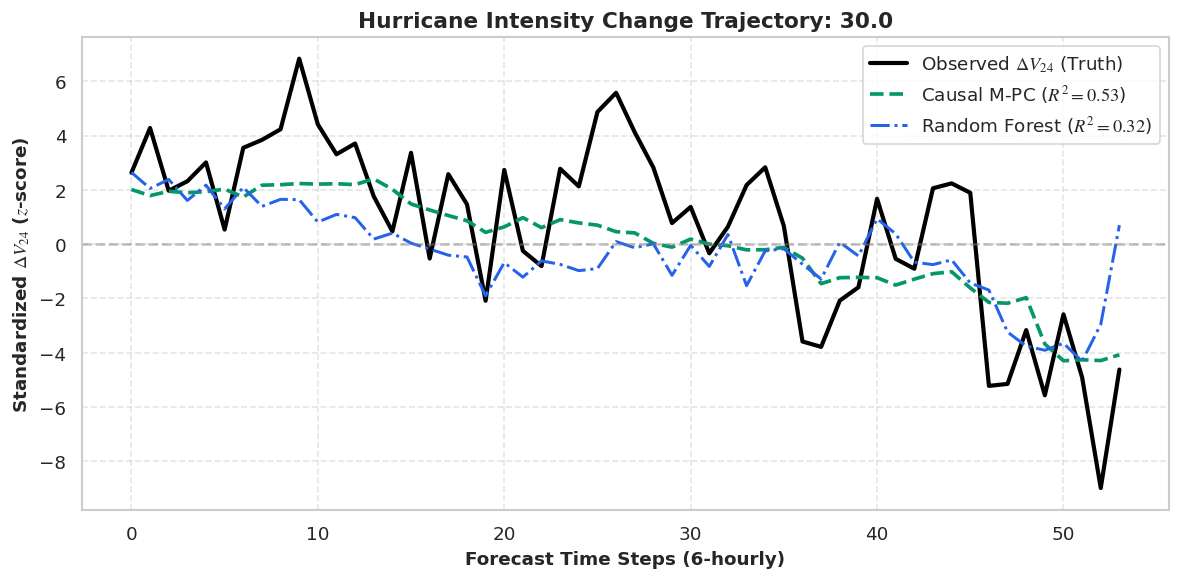

In [ ]:
# ==============================================================================
# Corrected Evaluation & Case Study Loop (Fixes Feature Index Shift)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# 1. Correct the feature indices by shifting them to match predictor-only matrices (X has no target column 0)
# Absolute index i in Tigramite corresponds to column i - 1 in X_tr / X_s
causal_indices_shifted = [i - 1 for i in peak_row['selected_indices'] if i > 0]

# Fit MLR with correctly aligned indices
mlr_causal_fixed = LinearRegression()
mlr_causal_fixed.fit(X_tr[:, causal_indices_shifted], y_tr)

# 2. Re-evaluate test storms with the corrected indices
storm_eval_records = []

for s_id, s_arr in test_dict.items():
    s_arr = np.asarray(s_arr)
    X_s, y_s = s_arr[:, 1:], s_arr[:, 0]
    valid_mask = (X_s != -999.0).all(axis=1) & (y_s != -999.0)
    X_s, y_s = X_s[valid_mask], y_s[valid_mask]

    if len(y_s) >= 8:
        pred_c = mlr_causal_fixed.predict(X_s[:, causal_indices_shifted])
        pred_rf = rf_best['Model'].predict(X_s[:, rf_best['Indices']])
        pred_r = corr_best['Model'].predict(X_s[:, corr_best['Indices']])

        storm_eval_records.append({
            'storm_id': s_id,
            'steps': len(y_s),
            'r2_causal': r2_score(y_s, pred_c),
            'r2_rf': r2_score(y_s, pred_rf),
            'r2_corr': r2_score(y_s, pred_r)
        })

df_test_storms = pd.DataFrame(storm_eval_records).sort_values('r2_causal', ascending=False)
print("\nTop Unseen Test Storms Ranked by Corrected Causal R²:")
display(df_test_storms.head(5))

# 3. Plot the top storm trajectory cleanly
best_storm_id = df_test_storms.iloc[0]['storm_id']
s_best = np.asarray(test_dict[best_storm_id])
X_b, y_b = s_best[:, 1:], s_best[:, 0]
valid_mask_b = (X_b != -999.0).all(axis=1) & (y_b != -999.0)
X_b, y_b = X_b[valid_mask_b], y_b[valid_mask_b]

pred_c_b = mlr_causal_fixed.predict(X_b[:, causal_indices_shifted])
pred_rf_b = rf_best['Model'].predict(X_b[:, rf_best['Indices']])
pred_r_b = corr_best['Model'].predict(X_b[:, corr_best['Indices']])

plt.figure(figsize=(10, 5), dpi=120)
plt.plot(y_b, label="Observed $\Delta V_{24}$ (Truth)", color="black", linewidth=2.5)
plt.plot(pred_c_b, label=f"Causal M-PC ($R^2={df_test_storms.iloc[0]['r2_causal']:.2f}$)", color="#059669", linewidth=2.2, linestyle="--")
plt.plot(pred_rf_b, label=f"Random Forest ($R^2={df_test_storms.iloc[0]['r2_rf']:.2f}$)", color="#2563eb", linewidth=1.8, linestyle="-.")
plt.axhline(0, color="gray", linestyle="--", alpha=0.5)

plt.title(f"Hurricane Intensity Change Trajectory: {best_storm_id}", fontsize=13, fontweight='bold')
plt.xlabel("Forecast Time Steps (6-hourly)", fontsize=11, fontweight='bold')
plt.ylabel("Standardized $\Delta V_{24}$ ($z$-score)", fontsize=11, fontweight='bold')
plt.legend(frameon=True, loc='best')
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

---

---

## 7. Physical Interpretability via SHAP Analysis

In numerical weather prediction and machine learning applications, interpretability is as critical as predictive skill. Because our causal feature selector feeds into a transparent linear architecture, we apply **SHAP (SHapley Additive exPlanations)** to decompose individual forecasts into exact physical attributions[cite: 1].

The resulting SHAP summary plots provide vital diagnostic insights[cite: 1]:
* **Global Feature Ranking (Y-axis)**: Identifies which thermodynamic and kinematic parameters dominate the variance of the forecast model[cite: 1].
* **Marginal Response (X-axis & Color)**: Quantifies how high versus low magnitudes of a driver (e.g., tropospheric moisture layers vs. deep vertical wind shear) modulate intensity changes[cite: 1].

*As detailed below, the isolated drivers exhibit physical behaviors consistent with established tropical dynamics—such as deep vertical wind shear acting as a primary vortex-tilting inhibitor to intensification.*[cite: 1]

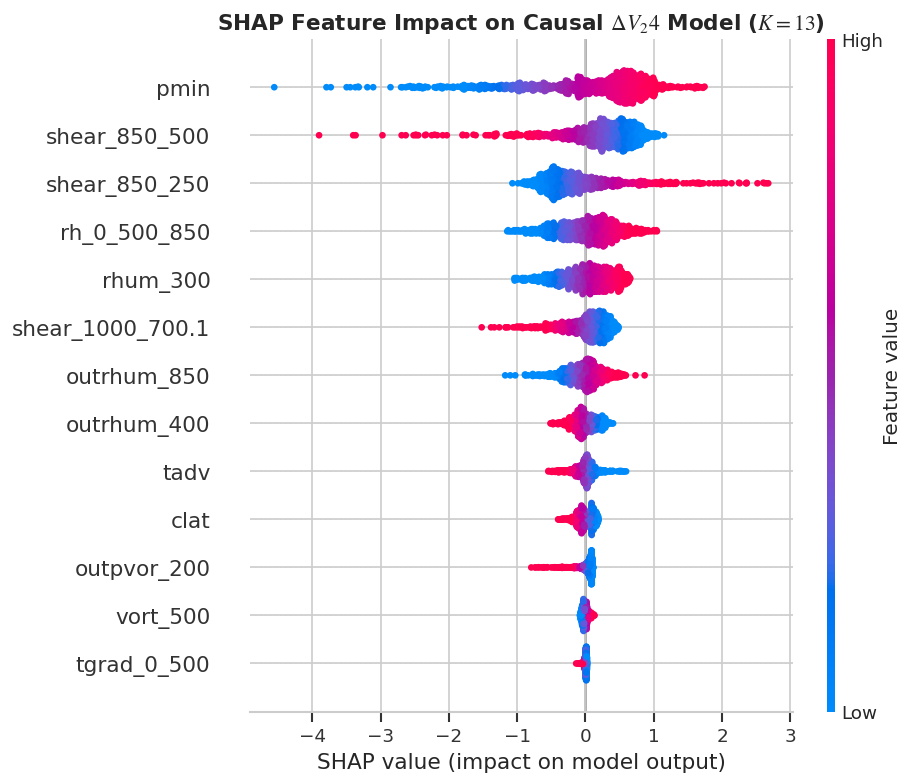

In [ ]:
# ==============================================================================
# Step 7: Model Interpretability with SHAP (SHapley Additive exPlanations)
# ==============================================================================
import shap
import matplotlib.pyplot as plt

# 1. Get the exact feature names corresponding to our shifted causal indices
causal_feature_names = [var_names[i] for i in peak_row['selected_indices']]

# 2. Initialize a SHAP Linear Explainer for our Causal MLR model
# We pass the training data subset as the background reference distribution
explainer = shap.LinearExplainer(
    mlr_causal_fixed,
    X_tr[:, causal_indices_shifted],
    feature_perturbation="interventional"
)

# 3. Compute SHAP values for the validation or test set
# Let's use the validation set to explain feature contributions
shap_values = explainer(X_val[:, causal_indices_shifted])

# 4. Plot the SHAP Summary (Bee Swarm Plot)
plt.figure(figsize=(10, 6), dpi=120)
shap.summary_plot(
    shap_values,
    X_val[:, causal_indices_shifted],
    feature_names=causal_feature_names,
    show=False
)
plt.title(f"SHAP Feature Impact on Causal $\Delta V_{24}$ Model ($K={len(causal_indices_shifted)}$)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---

## 8. Summary & Key Takeaways

This tutorial demonstrated how data-driven causal discovery can be successfully leveraged within atmospheric science workflows[cite: 1]. Key takeaways for Earth system scientists include:

* **Rigorous Treatment of Non-Stationarity:** Utilizing **M-PC** across disjoint multivariate time series respects atmospheric boundaries, avoiding the statistical artifacts associated with naive temporal concatenation[cite: 1].
* **Enforcing Physical Priors:** Integrating expert domain knowledge through custom link assumptions ensures that data-driven discovery remains bounded by known dynamical and thermodynamic laws[cite: 1].
* **Combating the Overfitting Trap:** While unconstrained high-dimensional models achieve high training variance, causal parsimoniousness yields superior out-of-sample stability and generalizability across unseen synoptic regimes[cite: 1].
* **Trust Through Explainability:** Combining causal feature extraction with additive attribution methods ensures that automated workflows remain transparent, interpretable, and physically defensible for operational meteorological applications[cite: 1].

---
## References

1. **Ganesh, S. S., F. I.-H. Tam, M. S. Gomez, M. McGraw, M. DeMaria, K. Musgrave, J. Runge, and T. Beucler**, 2026: *Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. **Weather and Forecasting**, 41 (7), 1359–1375, [https://doi.org/10.1175/WAF-D-25-0208.1](https://doi.org/10.1175/WAF-D-25-0208.1).[cite: 3]
2. **Ganesh, S. S., et al.**, 2026: *Supplementary Information (SI): Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. **Weather and Forecasting**, [https://doi.org/10.1175/WAF-D-25-0208.s1](https://doi.org/10.1175/WAF-D-25-0208.s1).[cite: 2, 3]
3. **Runge, J., P. Nowack, M. Kretschmer, S. Flaxman, and D. Sejdinovic**, 2019: *Detecting and quantifying causal associations in large nonlinear time series datasets*. **Science Advances**, 5 (11), eaau4996, [https://doi.org/10.1126/sciadv.aau4996](https://doi.org/10.1126/sciadv.aau4996).[cite: 3]
4. **DeMaria, M., and J. Kaplan**, 1994: *A Statistical Hurricane Intensity Prediction Scheme (SHIPS) for the Atlantic basin*. **Weather and Forecasting**, 9 (2), 209–220, [https://doi.org/10.1175/1520-0434(1994)009<0209:ASHIPS>2.0.CO;2](https://doi.org/10.1175/1520-0434(1994)009<0209:ASHIPS>2.0.CO;2).[cite: 3]
5. **Razin, M. N., C. J. Slocum, J. A. Knaff, P. J. Brown, and M. M. Bell**, 2023: *Tropical Cyclone Precipitation, Infrared, Microwave, and Environmental Dataset (TC PRIMED)*. **Bulletin of the American Meteorological Society**, 104 (11), E1980–E1998, [https://doi.org/10.1175/BAMS-D-21-0052.1](https://doi.org/10.1175/BAMS-D-21-0052.1).[cite: 3]